## Clustering: Interpretación, anomalías y exportación

Arquetipos de KMeans, outliers de DBSCAN, banderas de auditoría y artefacto para el reporte web

### Constantes

- `P_ALTO`, `P_BAJO`: percentiles que definen "alto" y "bajo" en las banderas
- `P_LEJOS`: percentil de distancia al centroide **dentro de cada arquetipo** que se considera atípico

In [1]:
P_ALTO, P_BAJO, P_LEJOS = 0.99, 0.10, 0.99

### Utilidades

In [2]:
NOTEBOOK = "c_interpretacion"
%run ../funciones.ipynb
%run funciones.ipynb

In [3]:
spark = crear_spark(NOTEBOOK)  # solo para guardar_tablas
d = pd.read_parquet(clust_dir / "etiquetas.parquet")
d["tipo"] = d.proveedor_key.str.split(":").str[0]
VARS = ["monto_total", "monto_mediano", "n_procesos", "n_entidades", "n_regiones", "n_familias", "meses_activos",
        "tasa_exito", "pct_postor_unico", "pct_directa", "hhi_entidades", "pct_bienes", "pct_servicios", "pct_obras",
        "es_consorcio", "disp_log_monto"]
print(f"{len(d):,} proveedores")

86,011 proveedores


---
### **1. Arquetipos (KMeans, k = 6)**

#### a. Nombres

- Se asignan por **reglas sobre el perfil**, no a mano por número de clúster: el nombre no depende de cómo KMeans
  numere los grupos

In [4]:
m = d.groupby("cluster_kmeans")[VARS].mean()
nombres, libres = {}, set(m.index)

def asignar(criterio, nombre):
    c = m.loc[list(libres), criterio].idxmax()
    nombres[c] = nombre; libres.discard(c)

asignar("n_procesos",       "Grandes proveedores recurrentes multientidad")
asignar("pct_postor_unico", "Adjudicatarios sin competencia (postor único / directa)")
asignar("pct_obras",        "Consorcios de obra pública")
asignar("es_consorcio",     "Consorcios de servicios y consultoría")
asignar("pct_bienes",       "Proveedores ocasionales de bienes")
asignar("n_procesos",       "Pymes recurrentes multirrubro")
d["arquetipo"] = d.cluster_kmeans.map(nombres)

#### b. Perfiles

In [5]:
monto = d.groupby("arquetipo").monto_total.sum()
perf = perfil(d, "arquetipo", VARS[:11]).assign(pct_monto=(100 * monto / monto.sum()).round(1))
perf = perf.join(d.groupby("arquetipo")[["pct_bienes", "pct_servicios", "pct_obras", "es_consorcio"]].mean().round(2)
                  .add_prefix("media_"))
perf.sort_values("pct_monto", ascending=False).round(2).T

arquetipo,Consorcios de obra pública,Grandes proveedores recurrentes multientidad,Pymes recurrentes multirrubro,Consorcios de servicios y consultoría,Adjudicatarios sin competencia (postor único / directa),Proveedores ocasionales de bienes
n,18574.00,3198.00,10349.00,26225.00,10804.00,16861.00
pct,21.60,3.70,12.00,30.50,12.60,19.60
monto_total,1829054.54,3773863.20,732100.00,176022.77,109225.94,119000.00
monto_mediano,1812520.51,147066.68,119641.00,175000.00,84000.00,80995.00
n_procesos,1.00,13.00,4.00,1.00,1.00,1.00
n_entidades,1.00,8.00,2.00,1.00,1.00,1.00
n_regiones,1.00,5.00,2.00,1.00,1.00,1.00
n_familias,1.00,3.00,2.00,1.00,1.00,1.00
meses_activos,1.00,10.00,3.00,1.00,1.00,1.00
tasa_exito,1.00,0.14,0.14,1.00,1.00,0.25


In [6]:
pd.crosstab(d.arquetipo, d.tipo, normalize="index").mul(100).round(1)

tipo,CONS,EXT,NOM,PN,RUC
arquetipo,,,,,
Adjudicatarios sin competencia (postor único / directa),9.7,18.7,0.0,49.4,22.2
Consorcios de obra pública,95.7,0.4,0.0,0.1,3.8
Consorcios de servicios y consultoría,89.9,0.3,0.0,6.8,3.0
Grandes proveedores recurrentes multientidad,0.0,0.0,0.0,10.9,89.1
Proveedores ocasionales de bienes,0.0,2.0,0.0,31.0,67.0
Pymes recurrentes multirrubro,0.0,1.0,0.0,19.2,79.8


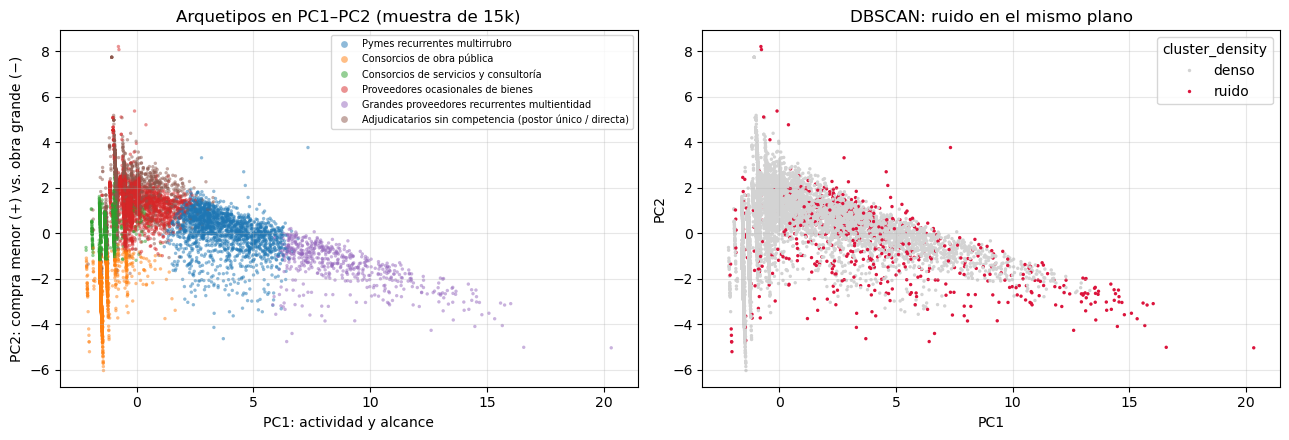

In [7]:
vis = d.sample(15_000, random_state=SEMILLA)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.scatterplot(data=vis, x="pc_1", y="pc_2", hue="arquetipo", s=6, alpha=.5, linewidth=0, ax=ax[0])
ax[0].set_title("Arquetipos en PC1–PC2 (muestra de 15k)"); ax[0].legend(fontsize=7, markerscale=2)
ax[0].set_xlabel("PC1: actividad y alcance"); ax[0].set_ylabel("PC2: compra menor (+) vs. obra grande (−)")
sns.scatterplot(data=vis, x="pc_1", y="pc_2", hue=vis.cluster_density.eq(-1).map({True: "ruido", False: "denso"}),
                palette={"denso": "lightgray", "ruido": "crimson"}, s=6, linewidth=0, ax=ax[1])
ax[1].set_title("DBSCAN: ruido en el mismo plano"); ax[1].set_xlabel("PC1"); ax[1].set_ylabel("PC2")
mostrar_fig("arquetipos_pca")

- **Lo que define los arquetipos es la forma jurídica y el objeto, más que el tamaño:** consorcio vs. empresa o persona,
  y obra vs. servicio vs. bien
- **Consorcios de obra pública** (21.6% de proveedores, **59.9% del monto**): un solo proceso de S/ 1.8M mediano; el
  consorcio se constituye para una licitación de obra y desaparece
- **Grandes proveedores recurrentes multientidad** (3.7%, **20.1% del monto**): 13 procesos, 8 entidades, 5 regiones,
  HHI 0.24; mayormente bienes (66%). Son los proveedores nacionales diversificados
- **Pymes recurrentes multirrubro** (12.0%, 12.9%): 4 procesos, 2 entidades, mezcla de bienes y servicios
- **Consorcios de servicios y consultoría** (30.5%, solo 2.9%): el grupo más numeroso y de menor monto por proveedor
- **Proveedores ocasionales de bienes** (19.6%, 1.8%): un proceso, 31% personas naturales
- **Adjudicatarios sin competencia** (12.6%, 2.4%): 91% postor único y 47% contratación directa; 49% personas naturales
  y 19% extranjeros (proveedores exclusivos, servicios personales)
- **En el plano PCA:** PC1 separa a los recurrentes (derecha) de los ocasionales; PC2 separa obra grande (abajo) de
  compra menor. El ruido se concentra a la derecha, entre los actores activos

#### c. Polarización del monto

In [8]:
orden = d.monto_total.sort_values(ascending=False).to_numpy()
conc = pd.DataFrame([(f"top {p:.1%}", orden[:max(1, int(p * len(orden)))].sum() / orden.sum())
                     for p in (0.001, 0.01, 0.05, 0.10, 0.50)], columns=["proveedores", "pct_del_monto"])
conc.assign(pct_del_monto=conc.pct_del_monto.mul(100).round(1))

,proveedores,pct_del_monto
0,top 0.1%,17.2
1,top 1.0%,46.8
2,top 5.0%,71.3
3,top 10.0%,81.8
4,top 50.0%,97.7


- **Concentración extrema:** el 1% de proveedores recibe el **46.8%** del monto, el 10% el 81.8%; la mitad inferior,
  apenas el 2.3%
- El 0.1% (86 proveedores) ya suma el 17.2%

---
### **2. Anomalías**

#### a. Ruido de DBSCAN

In [9]:
ruido = d.cluster_density.eq(-1)
comp = pd.concat([d[ruido][VARS].median(), d[~ruido][VARS].median()], axis=1, keys=["ruido", "resto"]).round(2)
lift = (d[ruido].arquetipo.value_counts(normalize=True) / d.arquetipo.value_counts(normalize=True)).round(2)
print(f"ruido: {ruido.sum():,} proveedores ({ruido.mean():.2%}) que suman el {d[ruido].monto_total.sum() / d.monto_total.sum():.1%} del monto")
display(comp.T)
lift.rename("sobrerrepresentación en el ruido (×)").to_frame()

ruido: 3,577 proveedores (4.16%) que suman el 30.1% del monto


,monto_total,monto_mediano,n_procesos,n_entidades,n_regiones,n_familias,meses_activos,tasa_exito,pct_postor_unico,pct_directa,hhi_entidades,pct_bienes,pct_servicios,pct_obras,es_consorcio,disp_log_monto
ruido,3419450.7,255500.0,4.0,2.0,1.0,2.0,3.0,0.32,0.33,0.16,0.66,0.0,0.33,0.0,0.0,0.82
resto,284400.0,180000.0,1.0,1.0,1.0,1.0,1.0,1.00,0.00,0.00,1.00,0.0,1.00,0.0,1.0,0.00


,sobrerrepresentación en el ruido (×)
arquetipo,
Adjudicatarios sin competencia (postor único / directa),1.38
Consorcios de obra pública,0.27
Consorcios de servicios y consultoría,0.03
Grandes proveedores recurrentes multientidad,6.68
Proveedores ocasionales de bienes,0.32
Pymes recurrentes multirrubro,3.75


- **El ruido no son microproveedores:** el 4.16% de proveedores concentra el **30.1% del monto**; su mediana es de 4
  procesos y S/ 3.4M, con 33% de postor único y montos muy dispares entre contratos
- **Dónde aparece:** grandes recurrentes **6.7×** y pymes recurrentes **3.8×** más que su peso; los consorcios casi nunca
  (0.03×), porque miles de ellos tienen vectores casi idénticos y forman regiones densas
- **Lectura:** ser atípico es una **combinación inusual** de escala, competencia y dispersión, propia de actores activos

#### b. Banderas descriptivas (PQ-C2)

| Bandera | Regla | Lectura |
|---|---|---|
| `b_monto_concentrado` | monto total ≥ p99, ≤ 2 procesos y HHI ≥ 0.9 | mucho dinero, pocas adjudicaciones, un solo cliente |
| `b_micro_masivo` | procesos ≥ p99 y monto mediano ≤ p10 | cientos de contratos de monto ínfimo (posible fraccionamiento) |
| `b_montos_dispares` | dispersión de log(monto) ≥ p99 | montos de órdenes de magnitud distintas (posible error de registro) |
| `b_lejos_centroide` | distancia al centroide ≥ p99 **de su arquetipo** | atípico respecto de sus pares |
| `es_ruido` | DBSCAN = −1 | sin 10 vecinos parecidos |

In [10]:
q = d[["monto_total", "n_procesos", "monto_mediano", "disp_log_monto"]].quantile([P_BAJO, P_ALTO])
d["b_monto_concentrado"] = ((d.monto_total >= q.monto_total[P_ALTO]) & (d.n_procesos <= 2) & (d.hhi_entidades >= .9)).astype(int)
d["b_micro_masivo"] = ((d.n_procesos >= q.n_procesos[P_ALTO]) & (d.monto_mediano <= q.monto_mediano[P_BAJO])).astype(int)
d["b_montos_dispares"] = (d.disp_log_monto >= q.disp_log_monto[P_ALTO]).astype(int)
d["b_lejos_centroide"] = (d.dist_centroide >= d.groupby("cluster_kmeans").dist_centroide.transform("quantile", P_LEJOS)).astype(int)
d["es_ruido"] = ruido.astype(int)
BANDERAS = ["b_monto_concentrado", "b_micro_masivo", "b_montos_dispares", "b_lejos_centroide", "es_ruido"]
d["n_senales"] = d[BANDERAS].sum(axis=1)

resumen_b = pd.DataFrame({"proveedores": d[BANDERAS].sum(),
                          "pct_en_ruido": [d.loc[d[b] == 1, "es_ruido"].mean() * 100 for b in BANDERAS],
                          "monto_total_MM": [d.loc[d[b] == 1, "monto_total"].sum() / 1e6 for b in BANDERAS]}).round(1)
print(f"umbrales: monto total p99 = S/ {q.monto_total[P_ALTO]:,.0f} | procesos p99 = {q.n_procesos[P_ALTO]:.0f} | "
      f"monto mediano p10 = S/ {q.monto_mediano[P_BAJO]:,.0f}")
display(resumen_b)
d.n_senales.value_counts().sort_index().to_frame("proveedores").T

umbrales: monto total p99 = S/ 39,883,734 | procesos p99 = 22 | monto mediano p10 = S/ 53,805


,proveedores,pct_en_ruido,monto_total_MM
b_monto_concentrado,552,12.9,71938.3
b_micro_masivo,6,100.0,37.5
b_montos_dispares,861,62.8,23644.8
b_lejos_centroide,865,30.5,41544.7
es_ruido,3577,100.0,73552.4


n_senales,0,1,2,3,4
proveedores,81070,4108,751,77,5


#### c. Casos prioritarios para revisión

In [11]:
cols = ["nombre", "tipo", "arquetipo", "monto_total", "n_procesos", "n_entidades", "hhi_entidades",
        "pct_postor_unico", "pct_directa", "n_senales"] + BANDERAS
prioritarios = (publicable(d[d.n_senales >= 3]).sort_values(["n_senales", "monto_total"], ascending=False)[cols])
print(f"proveedores con ≥ 3 señales: {len(prioritarios):,}")
prioritarios.head(15).assign(monto_total=lambda x: x.monto_total.map("{:,.0f}".format))

proveedores con ≥ 3 señales: 82


,nombre,tipo,arquetipo,monto_total,n_procesos,n_entidades,hhi_entidades,pct_postor_unico,pct_directa,n_senales,b_monto_concentrado,b_micro_masivo,b_montos_dispares,b_lejos_centroide,es_ruido
9649,CHINA CIVIL ENGINEERING CONSTRUCTION CORPORATION SUCURSAL DEL PERU,RUC,Grandes proveedores recurrentes multientidad,"496,168,435",2,2,1.000000,0.500000,0.000000,4,1,0,1,1,1
75372,LEONARDO S.P.A.,EXT,Pymes recurrentes multirrubro,"94,547,672",2,2,0.997862,1.000000,0.000000,4,1,0,1,1,1
10726,MILENIUM VELADI CORP.,RUC,Pymes recurrentes multirrubro,"76,683,629",2,1,1.000000,0.500000,0.500000,4,1,0,1,1,1
68245,PROCESADORA DE GAS PARIÑAS S.A.C,EXT,Pymes recurrentes multirrubro,"61,234,346",2,1,1.000000,1.000000,0.000000,4,1,0,1,1,1
63373,ROCHE FARMA (PERU) S.A.,RUC,Pymes recurrentes multirrubro,"48,696,820",2,1,1.000000,1.000000,1.000000,4,1,0,1,1,1
77591,J Y S SERVICIOS GENERALES SOCIEDAD ANONIMA CERRADA ¿ J Y S SERVICIOS GENERAL...,RUC,Consorcios de obra pública,"1,111,909,484",1,1,1.000000,0.000000,0.000000,3,1,0,0,1,1
39640,MEDIFARMA S A,RUC,Grandes proveedores recurrentes multientidad,"636,414,847",143,47,0.802400,0.021127,0.027972,3,0,0,1,1,1
7731,MAPFRE PERU COMPAÑIA DE SEGUROS Y REASEGUROS,RUC,Grandes proveedores recurrentes multientidad,"598,647,301",344,177,0.080768,0.049419,0.029070,3,0,0,1,1,1
66361,CONSORCIO PUENTES PIURA,CONS,Consorcios de obra pública,"533,262,101",1,1,1.000000,0.000000,0.000000,3,1,0,0,1,1
56853,VIPROSEG SOCIEDAD ANONIMA CERRADA - VIPROSEG S.A.C.,RUC,Pymes recurrentes multirrubro,"412,820,923",7,2,0.936034,0.142857,0.571429,3,0,0,1,1,1


In [12]:
pd.crosstab(prioritarios.arquetipo, prioritarios.tipo, margins=True)

tipo,CONS,EXT,RUC,All
arquetipo,,,,
Adjudicatarios sin competencia (postor único / directa),2,0,12,14
Consorcios de obra pública,11,3,11,25
Grandes proveedores recurrentes multientidad,0,0,6,6
Pymes recurrentes multirrubro,0,4,33,37
All,13,7,62,82


- **Monto concentrado** (552 proveedores): solo el 12.9% cae en el ruido, así que es un patrón **frecuente**, no aislado;
  por sí sola esta bandera no distingue un caso atípico
- **Micro-masivo** (6): el fraccionamiento en cientos de contratos ínfimos no es un patrón común en estos datos
- **Montos dispares** (861, 63% en el ruido): incluye posibles **errores de registro** en el SEACE (montos de órdenes de
  magnitud distintos para un mismo proveedor)
- **82 proveedores con ≥ 3 señales (0.1%)**: lista corta para revisión. Todos están en el ruido y 80 lejos de su
  centroide; 62 son empresas con RUC, 13 consorcios y 7 extranjeros; **ninguna persona natural**
- **Casos tipo en la lista:**
  - extranjeros adjudicados con postor único: lo esperable en proveedores exclusivos de tecnología o defensa
  - farmacéuticas y aseguradoras con decenas de entidades y montos muy dispersos
  - una empresa de servicios generales con S/ 1,112M en un solo proceso, que conviene verificar en el SEACE como
    posible error de registro antes de cualquier otra lectura

---
### **3. Respuestas a las preguntas de interés**

**PQ-C1. ¿Arquetipos o polarización?** Ambas cosas, en dos niveles:

- **Nivel 1, polarización:** con k = 2 (mejor silueta, 0.49) el mercado se parte en ~85% de proveedores ocasionales
  frente a ~15% recurrentes, y el 1% de proveedores recibe el 46.8% del monto. El dendrograma reproduce ese primer corte
- **Nivel 2, seis arquetipos** (k = 6, codo; ARI 0.75 con el jerárquico) definidos por forma jurídica y objeto
- **Matiz a la hipótesis de "megacontratistas multipropósito":** existen (3.7%, 20.1% del monto), pero el mayor bloque
  de dinero (59.9%) va a **consorcios de obra de un solo proceso**. La concentración del gasto pasa por obras grandes
  adjudicadas a figuras temporales, no por un puñado de empresas permanentes

**PQ-C2. ¿Qué perfiles son atípicos?**

- El ruido de DBSCAN (4.16%) concentra el 30.1% del monto y está en proveedores **activos**, no en los ocasionales
- "Mucho monto, pocos procesos, un solo cliente" afecta a 552 proveedores, pero es un patrón frecuente (obras grandes):
  solo combinado con otras señales distingue casos
- La **lista de priorización** son los 82 proveedores con ≥ 3 señales (0.1%): ruido, lejos de su arquetipo y con montos
  concentrados o muy dispares

---
### **4. Encuadre ético**

- **Señales, no acusaciones:** un proveedor con banderas es un caso **atípico respecto de sus pares**, que amerita
  revisión administrativa (OECE, OCI, Contraloría). **No** es evidencia de colusión, dolo, fraccionamiento ni corrupción
- **Explicaciones legítimas frecuentes:**
  - postor único en mercados regionales pequeños o rubros especializados
  - contratación directa por emergencia o proveedor único, supuestos previstos en la normativa de contrataciones
  - montos dispares por errores de registro en el SEACE, no por conducta del proveedor
  - consorcios de un solo proceso por diseño legal (se constituyen para una licitación)
- **Límites del dato:** sin estado del award ni historia de modificaciones (`01_Trans/d_recuento` §4); la resolución de
  entidades no fusiona RUC distintos con nombre parecido
- **Privacidad:** las personas naturales (`PN:`) aparecen sin nombre ni documento en tablas y exportaciones
- **Uso del ranking:** priorizar revisión, nunca sancionar ni excluir proveedores de procesos

---
### **5. Exportación para el reporte web**

- `data/artefactos/clustering_proveedores.parquet`: un archivo liviano (*calcular offline, explorar online*)
- Incluye etiquetas para k = 2…8 y ruido para la grilla de eps: los sliders de la web no recalculan nada

In [13]:
exp = publicable(d).rename(columns={"pc_1": "PCA_1", "pc_2": "PCA_2"})
KS = [c for c in exp.columns if c.startswith("kmeans_k")]
EPS_C = [c for c in exp.columns if c.startswith("ruido_eps_")]
exp = exp[["proveedor_key", "ruc", "nombre", "tipo", "region", "monto_total", "monto_mediano", "n_procesos",
           "n_entidades", "n_regiones", "n_familias", "hhi_entidades", "pct_postor_unico", "pct_directa",
           "pct_bienes", "pct_servicios", "pct_obras", "es_consorcio", "PCA_1", "PCA_2",
           "cluster_kmeans", "arquetipo", "cluster_density", "dist_centroide"] + BANDERAS + ["n_senales"] + KS + EPS_C]
ruta = artef_dir / "clustering_proveedores.parquet"
exp.to_parquet(ruta, index=False)
print(f"{ruta.relative_to(proyecto)}: {len(exp):,} filas × {exp.shape[1]} columnas | {ruta.stat().st_size / 2**20:.1f} MB")
assert exp.loc[exp.tipo == "PN", "nombre"].eq("PERSONA NATURAL").all()

data/artefactos/clustering_proveedores.parquet: 86,011 filas × 42 columnas | 5.9 MB


In [14]:
escritos = guardar_tablas({"arquetipos": perf.reset_index(), "concentracion_monto": conc,
                           "ruido_vs_resto": comp.reset_index(names="variable"),
                           "banderas": resumen_b.reset_index(names="bandera"),
                           "prioritarios": prioritarios.head(100).reset_index(drop=True)})

Escrito en 02_Clustering/temp/c_interpretacion/: arquetipos, concentracion_monto, ruido_vs_resto, banderas, prioritarios


In [15]:
verificar_salidas(escritos)

OK: 5 tablas (parquet + json) | 1 figuras: arquetipos_pca


---
### Cerrar sesión

In [16]:
spark.stop()